# Exploratory data analysis (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('df_cleaned_sample.csv')
df.head()

,Unnamed: 0,order_id,order_date,customer_id,customer_age,gender,customer_segment,city,state,product_id,...,payment_mode,sales_channel,acquisition_source,order_status,delivery_date,delivery_days,customer_rating,Cancelled_order,Processing_order,Shipped_order
0,0,ORD000001,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Cash on Delivery,Website,Instagram Ads,Delivered,2025-01-06,5.0,4.0,0,0,0
1,1,ORD000002,2025-01-01,CUST00076,36,Female,Loyal,Jaipur,Rajasthan,P004,...,Cash on Delivery,WhatsApp,Referral,Delivered,2025-01-07,6.0,NaN,0,0,0
2,2,ORD000003,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Debit Card,Instagram,Organic Search,Delivered,2025-01-03,2.0,4.0,0,0,0
3,3,ORD000004,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Debit Card,Marketplace,Direct,Delivered,2025-01-05,4.0,4.0,0,0,0
4,4,ORD000005,2025-01-02,CUST00391,23,Female,New,Jaipur,Rajasthan,P008,...,Net Banking,Website,Organic Search,Delivered,2025-01-05,3.0,NaN,0,0,0


In [2]:
## Fill nan value in delivered column through mean aggregate
delivered_df = df["order_status"] == "Delivered"

df.loc[delivered_df, "customer_rating"] = (
    df.loc[delivered_df]
    .groupby("gender")["customer_rating"]
    .transform(lambda x: x.fillna(round(x.mean(), 1)))
)

In [3]:
df

,Unnamed: 0,order_id,order_date,customer_id,customer_age,gender,customer_segment,city,state,product_id,...,payment_mode,sales_channel,acquisition_source,order_status,delivery_date,delivery_days,customer_rating,Cancelled_order,Processing_order,Shipped_order
0,0,ORD000001,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Cash on Delivery,Website,Instagram Ads,Delivered,2025-01-06,5.0,4.0,0,0,0
1,1,ORD000002,2025-01-01,CUST00076,36,Female,Loyal,Jaipur,Rajasthan,P004,...,Cash on Delivery,WhatsApp,Referral,Delivered,2025-01-07,6.0,4.0,0,0,0
2,2,ORD000003,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Debit Card,Instagram,Organic Search,Delivered,2025-01-03,2.0,4.0,0,0,0
3,3,ORD000004,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Debit Card,Marketplace,Direct,Delivered,2025-01-05,4.0,4.0,0,0,0
4,4,ORD000005,2025-01-02,CUST00391,23,Female,New,Jaipur,Rajasthan,P008,...,Net Banking,Website,Organic Search,Delivered,2025-01-05,3.0,4.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1495,ORD001496,2025-12-29,CUST00340,21,Unknow,New,Lucknow,Uttar Pradesh,P006,...,Debit Card,Marketplace,Referral,Shipped,NaN,NaN,NaN,0,0,1
1496,1496,ORD001497,2025-12-29,CUST00302,29,Female,Returning,Surat,Gujarat,P009,...,Credit Card,Instagram,Instagram Ads,Delivered,2026-01-03,5.0,5.0,0,0,0
1497,1497,ORD001498,2025-12-29,CUST00312,24,Female,New,Bengaluru,Karnataka,P004,...,UPI,Website,Instagram Ads,Processing,NaN,NaN,NaN,0,1,0
1498,1498,ORD001499,2025-12-30,CUST00063,22,Male,Returning,Kota,Rajasthan,P011,...,Net Banking,Instagram,Organic Search,Delivered,2026-01-06,7.0,4.0,0,0,0


In [7]:
df.drop(columns = ['Unnamed: 0'], inplace = True)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 1500 non-null   object 
 1   order_date               1500 non-null   object 
 2   customer_id              1500 non-null   object 
 3   customer_age             1500 non-null   int64  
 4   gender                   1500 non-null   object 
 5   customer_segment         1500 non-null   object 
 6   city                     1500 non-null   object 
 7   state                    1500 non-null   object 
 8   product_id               1500 non-null   object 
 9   product_name             1500 non-null   object 
 10  category                 1500 non-null   object 
 11  quantity                 1500 non-null   int64  
 12  unit_price_inr           1500 non-null   int64  
 13  original_unit_price_inr  1500 non-null   int64  
 14  discount_percent        

In [10]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['delivery_date'] = pd.to_datetime(df['delivery_date'])

In [ ]:
## EDA perform
## Requirement 1: Sales Performance Analysis

In [21]:
# Q1: Total Revenue
total_revenue = df["total_amount_inr"].sum()
print(f"Total Revenue: ₹{total_revenue:,.2f}")

Total Revenue: ₹702,787.85


In [22]:
# Q2: Total Unique Orders
total_orders = df["order_id"].nunique()
print("Total Orders:", total_orders)

Total Orders: 1500


In [23]:
# Q3: Average Order Value
aov = total_revenue / total_orders
print(f"Average Order Value:, {aov:,.2f}")

Average Order Value:, 468.53


In [27]:
# Q4 Month-wise revenue trend (Delivery has been successful)
delivered_df = df[df["order_status"] == "Delivered"]

monthly_revenue = (
    delivered_df.groupby(
        delivered_df["order_date"].dt.to_period("M")
    )["total_amount_inr"]
    .sum()
    .reset_index()
)

monthly_revenue.columns = ["Month", "Delivered_Revenue"]

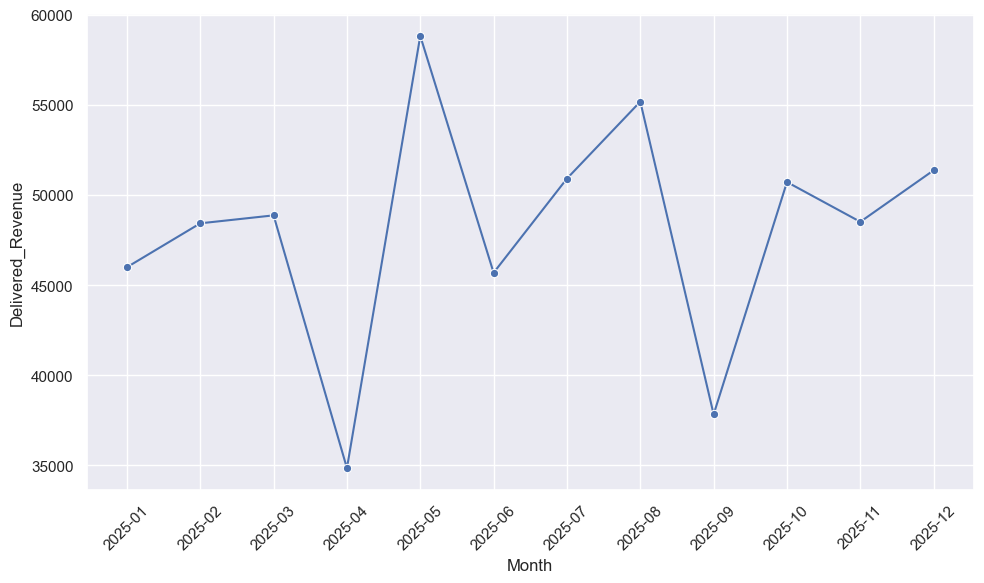

In [36]:
monthly_revenue["Month"] = monthly_revenue["Month"].astype(str)

plt.figure(figsize = (10,6))
sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Delivered_Revenue",
    marker="o"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
#Q5 Which Products and Category generate maximum revenue?
revenue_by_products = (
    delivered_df.groupby("product_name")["total_amount_inr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_by_products

,product_name,total_amount_inr
0,Steel Lunch Box,98448.85
1,Reusable Water Bottle,68149.95
2,Resistance Band Set,61334.00
3,Minimal Wallet,54603.10
4,Travel Pouch,48193.50
5,Desk Organizer,44874.55
6,Cotton Tote Bag,41144.80
7,Ceramic Mug,36884.35
8,Planner,35019.05
9,Notebook Set,34808.05


In [41]:
revenue_by_category = (
    delivered_df.groupby("category")["total_amount_inr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_by_category

,category,total_amount_inr
0,Lifestyle,166598.8
1,Accessories,143941.4
2,Home & Office,113598.3
3,Fitness,83155.6
4,Stationery,69827.1


In [43]:
#Q6 Which Cities and States generate maximum revenue?
revenue_by_cities = (
    delivered_df.groupby("city")["total_amount_inr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_by_cities

,city,total_amount_inr
0,Jaipur,112414.35
1,Delhi,73985.30
2,Mumbai,52876.90
3,Bengaluru,51094.65
4,Lucknow,46525.25
5,Hyderabad,43274.10
6,Pune,42989.40
7,Ahmedabad,41438.50
8,Indore,38518.60
9,Chandigarh,27284.70


In [44]:
revenue_by_state = (
    delivered_df.groupby("state")["total_amount_inr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_by_state

,state,total_amount_inr
0,Rajasthan,139534.55
1,Maharashtra,95866.30
2,Delhi,73985.30
3,Gujarat,61037.75
4,Karnataka,51094.65
5,Uttar Pradesh,46525.25
6,Telangana,43274.10
7,Madhya Pradesh,38518.60
8,Chandigarh,27284.70


In [45]:
# Requirement 2: Customer Analysis
#Q7 Total unique customers
total_customers = df['customer_id'].nunique()
print("Unique Customer:", total_customers)

Unique Customer: 511


In [46]:
#Q8 Based on New and Returning customer performance?
revenue_by_customer_segment = (
    delivered_df.groupby("customer_segment")["total_amount_inr"]
    .sum()
    .reset_index()
)

revenue_by_customer_segment

,customer_segment,total_amount_inr
0,Loyal,112487.60
1,New,217673.45
2,Returning,246960.15


In [47]:
order_by_customer_segment = (
    delivered_df.groupby("customer_segment")["order_id"]
    .count()
    .reset_index()
)

order_by_customer_segment

,customer_segment,order_id
0,Loyal,241
1,New,459
2,Returning,515


In [48]:
quantity_by_customer_segment = (
    delivered_df.groupby("customer_segment")["quantity"]
    .sum()
    .reset_index()
)

quantity_by_customer_segment

,customer_segment,quantity
0,Loyal,351
1,New,668
2,Returning,751


In [49]:
#Q9 Which customer has more spend?
top_spending_customers = (
    delivered_df.groupby("customer_id")
    .agg(
        Total_Spending=("total_amount_inr", "sum"),
        Total_Orders=("order_id", "nunique")
    )
    .sort_values("Total_Spending", ascending=False)
    .reset_index()
)

top_spending_customers.head(10)


,customer_id,Total_Spending,Total_Orders
0,CUST00111,14168.30,26
1,CUST00520,9273.00,16
2,CUST00096,6747.10,13
3,CUST00655,6562.65,13
4,CUST00434,6169.90,18
5,CUST00318,5837.10,9
6,CUST00624,5080.25,10
7,CUST00601,4979.65,14
8,CUST00521,4932.75,9
9,CUST00557,4629.70,7


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("half_analysis.csv")
df

,Unnamed: 0,order_id,order_date,customer_id,customer_age,gender,customer_segment,city,state,product_id,...,payment_mode,sales_channel,acquisition_source,order_status,delivery_date,delivery_days,customer_rating,Cancelled_order,Processing_order,Shipped_order
0,0,ORD000001,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Cash on Delivery,Website,Instagram Ads,Delivered,2025-01-06,5.0,4.0,0,0,0
1,1,ORD000002,2025-01-01,CUST00076,36,Female,Loyal,Jaipur,Rajasthan,P004,...,Cash on Delivery,WhatsApp,Referral,Delivered,2025-01-07,6.0,4.0,0,0,0
2,2,ORD000003,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Debit Card,Instagram,Organic Search,Delivered,2025-01-03,2.0,4.0,0,0,0
3,3,ORD000004,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,...,Debit Card,Marketplace,Direct,Delivered,2025-01-05,4.0,4.0,0,0,0
4,4,ORD000005,2025-01-02,CUST00391,23,Female,New,Jaipur,Rajasthan,P008,...,Net Banking,Website,Organic Search,Delivered,2025-01-05,3.0,4.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1495,ORD001496,2025-12-29,CUST00340,21,Unknow,New,Lucknow,Uttar Pradesh,P006,...,Debit Card,Marketplace,Referral,Shipped,NaN,NaN,NaN,0,0,1
1496,1496,ORD001497,2025-12-29,CUST00302,29,Female,Returning,Surat,Gujarat,P009,...,Credit Card,Instagram,Instagram Ads,Delivered,2026-01-03,5.0,5.0,0,0,0
1497,1497,ORD001498,2025-12-29,CUST00312,24,Female,New,Bengaluru,Karnataka,P004,...,UPI,Website,Instagram Ads,Processing,NaN,NaN,NaN,0,1,0
1498,1498,ORD001499,2025-12-30,CUST00063,22,Male,Returning,Kota,Rajasthan,P011,...,Net Banking,Instagram,Organic Search,Delivered,2026-01-06,7.0,4.0,0,0,0


In [8]:
delivered_df = df[df["order_status"] == "Delivered"]

In [9]:
#Q10 Rating by category?
rating_by_category = (
    delivered_df.groupby("category")["customer_rating"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

rating_by_category

,category,customer_rating
0,Accessories,3.983537
1,Lifestyle,3.895341
2,Stationery,3.873214
3,Home & Office,3.841767
4,Fitness,3.817778


In [13]:
# Requirement 3: Marketing Analysis
#Q11 Which social media platform placed maximum orders (Website, Instagram, Marketplace and WhatsApp)?

Orders_by_social_media = (
    delivered_df.groupby("sales_channel")["order_id"]
    .count()
    .sort_values(ascending=False)
    .reset_index()
)
Orders_by_social_media


,sales_channel,order_id
0,Website,459
1,Instagram,326
2,Marketplace,284
3,WhatsApp,146


In [20]:
#Q12 Which acquisition sources attract more customers?
customers_by_acquisition_sources = (
    delivered_df.groupby("acquisition_source")
    .agg(
        Total_customer=("customer_id", "nunique")
    )
    .sort_values("Total_customer", ascending=False)
    .reset_index()
)

customers_by_acquisition_sources

,acquisition_source,Total_customer
0,Instagram Ads,239
1,Organic Search,209
2,Referral,157
3,Direct,152
4,Influencer,136


In [21]:
#Q13 Which channel has max average order value?

AOV_by_social_media = (
    delivered_df.groupby("sales_channel")["total_amount_inr"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
AOV_by_social_media

,sales_channel,total_amount_inr
0,Marketplace,496.405458
1,Website,477.853922
2,Instagram,463.010736
3,WhatsApp,451.134247


In [23]:
#Requirement 4: Order and Delivery Analysis
#Q14 Delivered, Cancelled, Returned, Shipped and Processing orders count?
Order_status = df["order_status"].value_counts()
Order_status

order_status
Delivered     1215
Cancelled      100
Shipped         81
Returned        58
Processing      46
Name: count, dtype: int64

In [24]:
#Q15 Order cancellation rate found?
Order_cancellation_rate = (
    (df["order_status"] == "Cancelled").sum()
    / df["order_id"].nunique()
) * 100

print(round(Order_cancellation_rate, 2), "%")

6.67 %


In [25]:
#Q16 Return rate found?
Order_return_rate = (
    (df["order_status"] == "Returned").sum()
    / df["order_id"].nunique()
) * 100

print(round(Order_return_rate, 2), "%")

3.87 %


In [28]:
#Q17 Average delivery time?
Average_delivery_time = df["delivery_days"].mean()

print(f"Average delivery time:, {Average_delivery_time:.2f}")

Average delivery time:, 4.43


In [33]:
#Q18 Is there relationship between delivery time and customer rating?

delivered_df = df[df["order_status"] == "Delivered"].copy()

correlation = delivered_df[
    ["delivery_days", "customer_rating"]
].corr()

print(correlation)

                 delivery_days  customer_rating
delivery_days         1.000000        -0.032555
customer_rating      -0.032555         1.000000


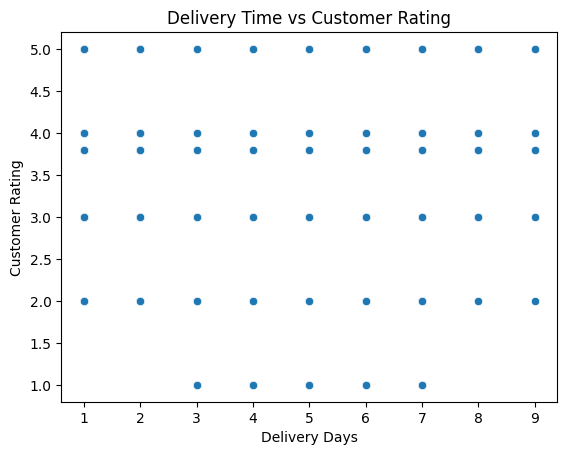

In [34]:
sns.scatterplot(
    data=delivered_df,
    x="delivery_days",
    y="customer_rating"
)

plt.title("Delivery Time vs Customer Rating")
plt.xlabel("Delivery Days")
plt.ylabel("Customer Rating")
plt.show()

In [36]:
#Requirement 5: Discount Analysis
#Q19 Give discount for how many orders?

discounted_orders = df[df["discount_amount_inr"] > 0]["order_id"].nunique()
print("Discounted Orders:", discounted_orders)

Discounted Orders: 1121


In [37]:
#Q20 Which discount percent is common?
common_discount = df[df["discount_percent"] > 0]["discount_percent"].mode()[0]
print("Most Common Discount:", common_discount, "%")

Most Common Discount: 10 %


In [38]:
#Q21 High Discount orders revenue?
high_discount = df[df["discount_percent"] >= 20]

high_discount_revenue = high_discount["total_amount_inr"].sum()

print("High-Discount Orders:", high_discount["order_id"].nunique())
print("High-Discount Revenue:", round(high_discount_revenue, 2))

High-Discount Orders: 114
High-Discount Revenue: 44834.4


In [40]:
#Q22 Is higher discount is accociate through larger order?
correlation = df[["discount_percent", "order_value_inr"]].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))

Correlation: -0.121


In [41]:
#Q23 Is need for improve discount strategy?
df["discount_group"] = pd.cut(
    df["discount_percent"],
    bins=[-1, 0, 10, 20, 100],
    labels=["No Discount", "1–10%", "11–20%", "Above 20%"]
)

discount_analysis = df.groupby("discount_group", observed=False).agg(
    Orders=("order_id", "nunique"),
    Revenue=("total_amount_inr", "sum"),
    Avg_Order_Value=("order_value_inr", "mean")
).round(2).reset_index()

print(discount_analysis)

  discount_group  Orders    Revenue  Avg_Order_Value
0    No Discount     379  195652.00           471.17
1          1–10%     704  328580.50           421.63
2         11–20%     417  178555.35           384.52
3      Above 20%       0       0.00              NaN


In [42]:
df.to_csv("analysis_unileaf_startup.csv")

,order_id,order_date,customer_id,customer_age,gender,customer_segment,city,state,product_id,product_name,...,sales_channel,acquisition_source,order_status,delivery_date,delivery_days,customer_rating,Cancelled_order,Processing_order,Shipped_order,discount_group
0,ORD000001,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,Reusable Water Bottle,...,Website,Instagram Ads,Delivered,2025-01-06,5.0,4.0,0,0,0,1–10%
1,ORD000002,2025-01-01,CUST00076,36,Female,Loyal,Jaipur,Rajasthan,P004,Scented Candle,...,WhatsApp,Referral,Delivered,2025-01-07,6.0,4.0,0,0,0,11–20%
2,ORD000003,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,Reusable Water Bottle,...,Instagram,Organic Search,Delivered,2025-01-03,2.0,4.0,0,0,0,No Discount
3,ORD000004,2025-01-01,CUST00111,29,Male,New,Bengaluru,Karnataka,P001,Reusable Water Bottle,...,Marketplace,Direct,Delivered,2025-01-05,4.0,4.0,0,0,0,1–10%
4,ORD000005,2025-01-02,CUST00391,23,Female,New,Jaipur,Rajasthan,P008,Travel Pouch,...,Website,Organic Search,Delivered,2025-01-05,3.0,4.0,0,0,0,1–10%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,ORD001496,2025-12-29,CUST00340,21,Unknow,New,Lucknow,Uttar Pradesh,P006,Notebook Set,...,Marketplace,Referral,Shipped,NaT,NaN,NaN,0,0,1,1–10%
1496,ORD001497,2025-12-29,CUST00302,29,Female,Returning,Surat,Gujarat,P009,Ceramic Mug,...,Instagram,Instagram Ads,Delivered,2026-01-03,5.0,5.0,0,0,0,1–10%
1497,ORD001498,2025-12-29,CUST00312,24,Female,New,Bengaluru,Karnataka,P004,Scented Candle,...,Website,Instagram Ads,Processing,NaT,NaN,NaN,0,1,0,11–20%
1498,ORD001499,2025-12-30,CUST00063,22,Male,Returning,Kota,Rajasthan,P011,Resistance Band Set,...,Instagram,Organic Search,Delivered,2026-01-06,7.0,4.0,0,0,0,11–20%


In [10]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'customer_age', 'gender',
       'customer_segment', 'city', 'state', 'product_id', 'product_name',
       'category', 'quantity', 'unit_price_inr', 'original_unit_price_inr',
       'discount_percent', 'discount_amount_inr', 'shipping_cost_inr',
       'order_value_inr', 'total_amount_inr', 'payment_mode', 'sales_channel',
       'acquisition_source', 'order_status', 'delivery_date', 'delivery_days',
       'customer_rating', 'Cancelled_order', 'Processing_order',
       'Shipped_order'],
      dtype='object')